# Lab 12A: Attention and position

## ✅ Solution version

All `???` gaps are filled in, and a **Solution and discussion** box follows every set of questions. Your own numbers will differ somewhat from run to run; what matters is whether you can explain the patterns.

This week's lab consists of **two short notebooks** on the main ideas of the lecture:

| Notebook | Question |
|---|---|
| **12A** Attention and position | What does attention compute, and why does a Transformer need position embeddings? |
| **12B** A tiny Vision Transformer | How is an image turned into tokens, and how does a ViT compare with a CNN when data is limited? |

Both are meant to be quick. **Use the rest of the session for your project.**

**Theory ↔ code.** As in the previous labs, the tables marked **🔗 Theory ↔ code** show how the equations
from the lecture map to lines of PyTorch.

**Cells marked 🛠️ TASK contain gaps (`???`) that you must fill in.** Each comes with a test cell; don't
move on until the tests pass. Write down your ✍️ **Prediction** before running an experiment.

---
## This notebook

| Part | You will… |
|---|---|
| 1. Attention as a database lookup | implement $\text{softmax}(QK^T/\sqrt{d_k})\,V$ and use it to look up images in a small "database" |
| 2. Self-attention ignores order | check that shuffling the tokens only shuffles the output |
| 3. Position embeddings | implement the sinusoidal position embeddings and see how they fix Part 2 |
| 4. Why patches? | count the size of the attention matrix for pixels, patches and Swin's windows (on paper) |
| 5. Exam-style questions | check your understanding |

Nothing is trained in this notebook, so a CPU is fine.

## Setup

Using device: cpu


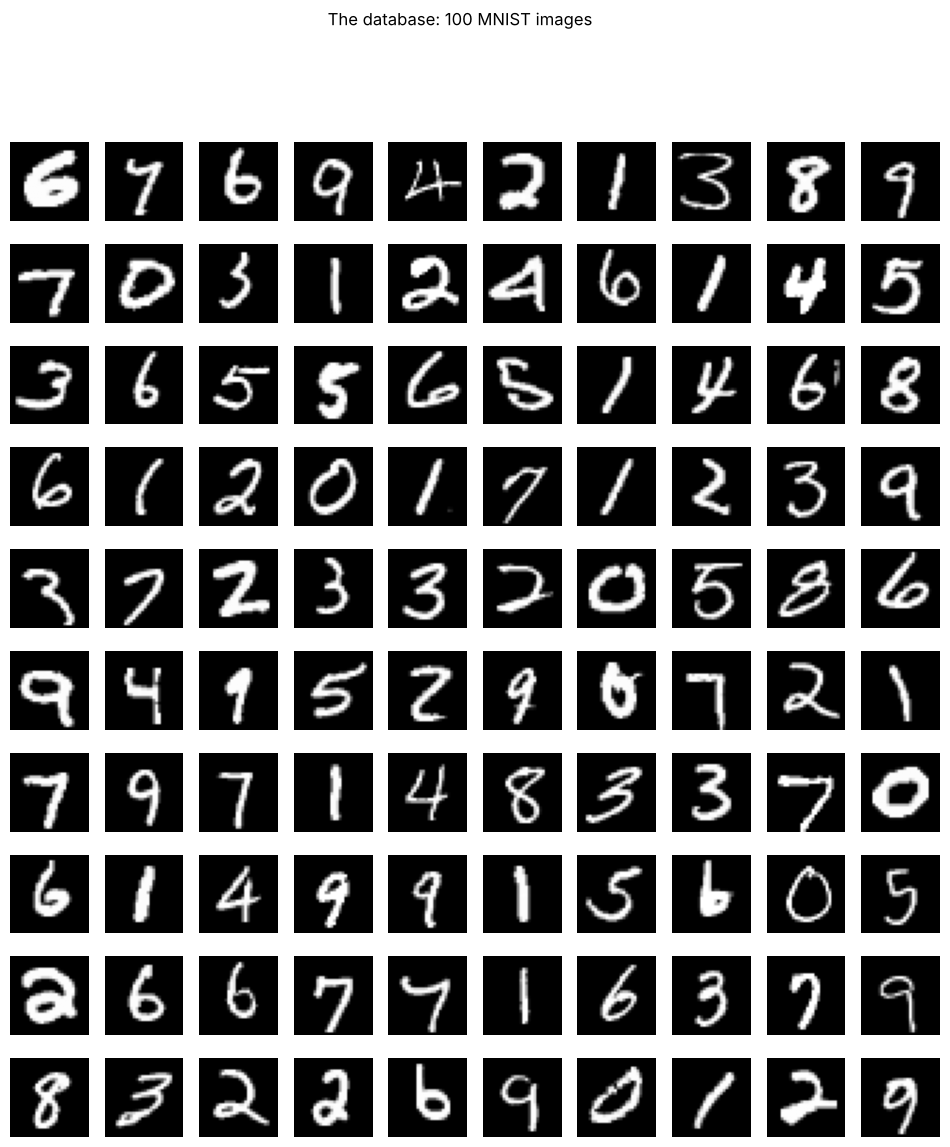

In [1]:
import math
import random
import time

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

import torchvision

mnist = torchvision.datasets.MNIST('.', train=True, download=True)
images = mnist.data.float() / 255                  # (60000, 28, 28), pixels in [0, 1]
labels = mnist.targets

# Our "database": 100 random MNIST images, each flattened to a vector of 784 pixels
set_seed(42)
db_idx = torch.randperm(len(images))[:100]
database = images[db_idx].reshape(100, -1)         # (100, 784)
db_labels = labels[db_idx]


def show_images(x, title=None, ncol=10):
    # x: (n, 784) or (784,)
    x = x.reshape(-1, 28, 28)
    n = len(x)
    nrow = math.ceil(n / ncol)
    fig, axs = plt.subplots(nrow, min(n, ncol), figsize=(1.2 * min(n, ncol), 1.3 * nrow), squeeze=False)
    for ax in axs.flat:
        ax.axis('off')
    for k in range(n):
        axs.flat[k].imshow(x[k], cmap='gray')
    if title:
        fig.suptitle(title)
    plt.show()


show_images(database, 'The database: 100 MNIST images')

---
# Part 1 — Attention as a database lookup

The lecture describes attention as a **differentiable database lookup** (Section 2.1). The database holds
key–value pairs. A query is compared with every key; the better a key matches, the more of its value we
retrieve:

$$\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{QK^T}{\sqrt{d_k}}\right) V$$

* **lookup:** the attention weights $\text{softmax}(QK^T/\sqrt{d_k})$ say how much we want of each entry;
* **retrieval:** multiplying the weights by $V$ gives a weighted sum of the values.

Here the **values** are the 100 images of our database: $V$ has shape (100, 784).

### 🛠️ TASK 1: Scaled dot-product attention

**🔗 Theory ↔ code**

| Lecture | Code | Shape |
|---|---|---|
| $QK^T$ (every query against every key) | `Q @ K.T` | (n_q, n_k) |
| $\sqrt{d_k}$ | `math.sqrt(d_k)` | |
| softmax over the keys (each row sums to 1) | `F.softmax(..., dim=-1)` | (n_q, n_k) |
| weights times $V$: the weighted sum of the values | `weights @ V` | (n_q, d_v) |

In [2]:
def attention(Q, K, V):
    # Q: (n_q, d_k), K: (n_k, d_k), V: (n_k, d_v)
    d_k = Q.shape[-1]
    weights = F.softmax(Q @ K.T / math.sqrt(d_k), dim=-1)   # lookup:    softmax(Q K^T / sqrt(d_k))      (n_q, n_k)
    output = weights @ V                                    # retrieval: weights V                        (n_q, d_v)
    return output, weights

In [3]:
# Test for Task 1
_Q, _K, _V = torch.randn(3, 8), torch.randn(5, 8), torch.randn(5, 6)
_out, _w = attention(_Q, _K, _V)
assert _w.shape == (3, 5) and _out.shape == (3, 6), f'wrong shapes: weights {tuple(_w.shape)}, output {tuple(_out.shape)}'
assert torch.allclose(_w.sum(-1), torch.ones(3), atol=1e-5), 'each row of the weights should sum to 1'
assert torch.allclose(_out, F.scaled_dot_product_attention(_Q, _K, _V), atol=1e-5), "the result differs from PyTorch's attention"
print('✅ Task 1 passed')

✅ Task 1 passed


### 1a. A hard lookup: one-hot keys

The simplest database gives every entry a unique **one-hot key**: entry $i$ has a key with a 1 in position $i$
and 0 elsewhere. To look up entry 10, we use the one-hot vector for 10 as the query. Then $QK^T$ is 1 for the
key of entry 10 and 0 for all others.

We shuffle the database first, so we no longer know *where* entry 10 is: the lookup must find it by its key.
The query is multiplied by a **sharpness** factor $s$.

✍️ **Prediction:** what will be retrieved with $s = 1$? And with $s = 100$?

s = 1: largest attention weight 0.01


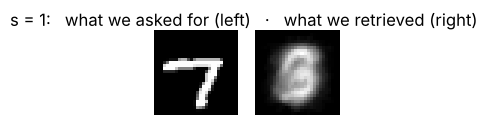

s = 10: largest attention weight 0.03


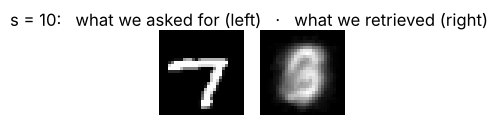

s = 100: largest attention weight 1.00


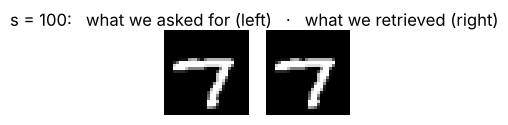

In [4]:
perm = torch.randperm(100)
K = torch.eye(100)[perm]            # one-hot keys, shuffled
V = database[perm]                  # the values, shuffled in the same way (key i belongs to image i)

for s in [1, 10, 100]:
    Q = s * torch.eye(100)[[10]]    # query: the one-hot vector for entry 10, times s   (1, 100)
    output, weights = attention(Q, K, V)
    print(f's = {s}: largest attention weight {weights.max():.2f}')
    show_images(torch.cat([database[10:11], output]), f's = {s}:   what we asked for (left)   ·   what we retrieved (right)', ncol=2)

### Questions 1a

1. Why is the retrieval blurry for $s = 1$? (Hint: compute the scores $QK^T/\sqrt{d_k}$ by hand: what are they
   for the matching key and for the other 99 keys, and what does the softmax make of that?)
2. Why does a larger $s$ give a sharper lookup? How is this related to the lecture's remark that, without the
   division by $\sqrt{d_k}$, the softmax would *saturate*?

> ### ✅ Solution and discussion
> 1. The score is $1/\sqrt{100} = 0.1$ for the matching key and $0$ for the 99 others. The softmax turns these almost equal scores
>    into almost equal weights: $e^{0.1}/(e^{0.1} + 99) \approx 0.011$ for the right image, against 0.010 for each other image. The
>    result is (nearly) the average of all 100 images: a blur.
> 2. A larger $s$ makes the difference between the scores larger ($s/10$ against 0), and the softmax turns large differences into
>    weights close to 0 and 1: for $s = 100$, the matching key gets a weight of about 0.99, so the lookup becomes a hard one. This is
>    exactly the *saturation* the lecture warns about: when the scores are large, the softmax is nearly one-hot. That is useful
>    here, but during training a saturated softmax has nearly zero gradient. Dividing by $\sqrt{d_k}$ keeps the scores from growing
>    with the dimension of the keys; how sharp the attention becomes is then *learned* (through $W_q$ and $W_k$).

### 1b. A content-based lookup: the keys are the images themselves

One-hot keys only work if we already know the "index" we want. In a Transformer, keys and queries are
computed from the **content** of the tokens ($K = XW_k$, $Q = XW_q$), so a query finds the entries whose
content matches. Let's mimic that without any training: we use the database images themselves as keys
(scaled to length 1), and a **new** MNIST image that is not in the database as the query.

✍️ **Prediction:** which database images will get the largest attention weights?

Query 0: digit 7.   Top-8 database digits: [9, 9, 9, 9, 7, 9, 7, 7]   weights: [0.15, 0.11, 0.1, 0.07, 0.06, 0.06, 0.05, 0.04]


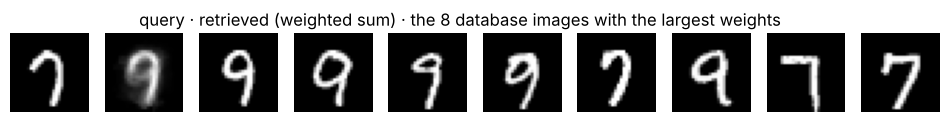

Query 1: digit 7.   Top-8 database digits: [2, 2, 2, 2, 2, 4, 6, 2]   weights: [0.08, 0.05, 0.05, 0.04, 0.04, 0.03, 0.03, 0.03]


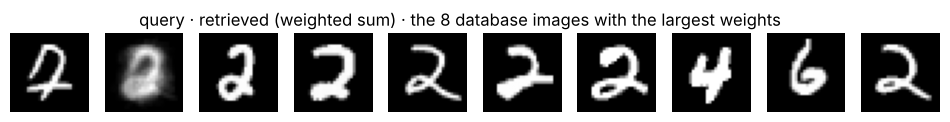

Query 2: digit 0.   Top-8 database digits: [0, 5, 6, 4, 0, 4, 3, 0]   weights: [0.1, 0.06, 0.05, 0.05, 0.04, 0.04, 0.03, 0.03]


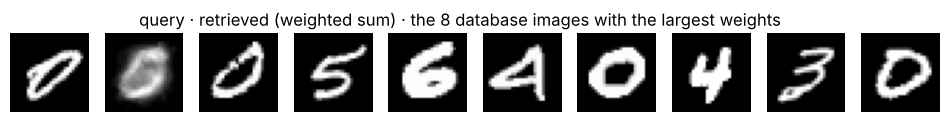

Query 3: digit 7.   Top-8 database digits: [7, 7, 5, 5, 0, 4, 7, 0]   weights: [0.25, 0.23, 0.03, 0.02, 0.02, 0.02, 0.02, 0.02]


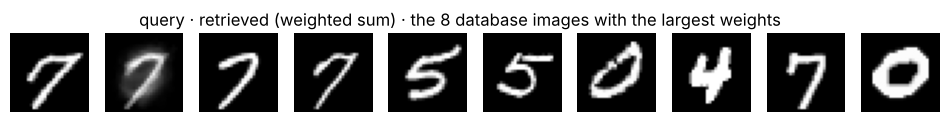

Query 4: digit 2.   Top-8 database digits: [7, 2, 2, 2, 0, 8, 6, 3]   weights: [0.08, 0.08, 0.06, 0.05, 0.04, 0.03, 0.02, 0.02]


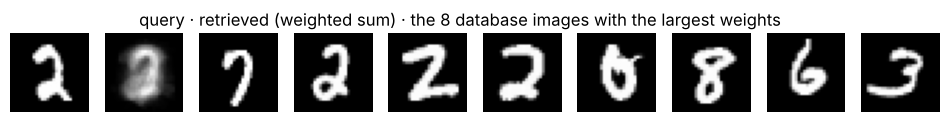

In [5]:
K = F.normalize(database, dim=1)            # keys: the database images, scaled to length 1     (100, 784)
V = database                                # values: the images                                (100, 784)

set_seed(1)
query_idx = torch.randperm(len(images))[:5]
query_idx = query_idx[~torch.isin(query_idx, db_idx)]
queries = F.normalize(images[query_idx].reshape(len(query_idx), -1), dim=1)

s = 300                                     # sharpness (try 30, 300 and 3000)
output, weights = attention(s * queries, K, V)

for q in range(len(query_idx)):
    top = weights[q].argsort(descending=True)[:8]
    print(f'Query {q}: digit {labels[query_idx[q]].item()}.   Top-8 database digits: {db_labels[top].tolist()}   '
          f'weights: {[round(w, 2) for w in weights[q, top].tolist()]}')
    show_images(torch.cat([images[query_idx[q]].reshape(1, -1), output[q:q + 1], database[top]]),
                'query · retrieved (weighted sum) · the 8 database images with the largest weights', ncol=10)

### Questions 1b

1. Do the database images with the largest weights show the same digit as the query? Why does a dot product
   between two (normalised) images measure how similar they are?
2. The retrieved image is a weighted sum of database images. When does it look like a single digit, and when
   like a blend? Try $s = 30$ and $s = 3000$.
3. Here the keys and queries are fixed: raw pixels. In a Transformer they are $K = XW_k$ and $Q = XW_q$, with
   learned $W_k$ and $W_q$. What does learning these matrices make possible?

> ### ✅ Solution and discussion
> 1. Often, but not always. In the reference run, the largest weight went to the right digit for queries 2 and 3 (a 0 and a 7), and
>    the next three for query 4 (a 2) were right too; but query 0 (a 7) matched mostly 9s and query 1 (another 7) mostly 2s. For vectors of length 1, the dot product is the cosine of the angle between
>    them: it is large when bright pixels coincide, i.e. when the images *look* alike pixel by pixel (the same idea as the k-NN in
>    Lab 10, but on raw pixels). A slanted 7 and a 9 share many bright pixels, so pixel similarity is a crude notion of "same digit".
> 2. With $s = 30$ the weights are spread over many images, so the result is a blend (an "average digit" of the most similar
>    ones). With $s = 3000$ almost all weight goes to the single best match, which is retrieved almost exactly (a hard lookup).
> 3. The model can learn **which** aspects of the content should match: for example, that a token looking for "the object's
>    head" should match tokens showing a head, even if their raw pixels differ. Raw pixel similarity is a fixed, crude notion of
>    "match"; learned projections let every head of every layer define its own notion, and how sharp it should be.

---
# Part 2 — Self-attention ignores order

In **self-attention**, the queries, keys and values all come from the same sequence of tokens $X$
($Q = XW_q$, $K = XW_k$, $V = XW_v$). We use PyTorch's `nn.MultiheadAttention` on a sequence of 6 random
tokens, run it once on the tokens in their original order and once on the **shuffled** tokens.

✍️ **Prediction:** how will the two outputs be related?

In [6]:
set_seed(0)
d = 16
self_attention = nn.MultiheadAttention(d, num_heads=2, batch_first=True)
X = torch.randn(1, 6, d)                          # one sequence of 6 tokens
shuffle = torch.tensor([3, 0, 5, 1, 4, 2])        # a permutation of the 6 positions

with torch.no_grad():
    out, _ = self_attention(X, X, X)
    X_shuffled = X[:, shuffle]
    out_shuffled, _ = self_attention(X_shuffled, X_shuffled, X_shuffled)

print('Output for the shuffled tokens == the original output, shuffled the same way?',
      torch.allclose(out_shuffled, out[:, shuffle], atol=1e-6))

Output for the shuffled tokens == the original output, shuffled the same way? True


### Questions 2

1. What does the result mean: does self-attention know in which order the tokens came?
2. Why is this a problem for a sentence ("the dog bit the man" versus "the man bit the dog")? Why is it an
   even bigger problem when the tokens are the patches of an image?

> ### ✅ Solution and discussion
> 1. No. Shuffling the input only shuffles the output in the same way: every token's output depends on the *set* of other tokens,
>    not on where they are. (The lecture calls this permutation invariance; strictly speaking the output is permutation
>    *equivariant*: it is shuffled along with the input.)
> 2. Both sentences contain the same words, so without position information every word gets the same output in both, and the
>    model cannot tell who bit whom. For an image, the patches of a scrambled image would give exactly the same token outputs as
>    the original image: the model could not see the shape of anything, only which patches occur.

---
# Part 3 — Position embeddings

The fix is to **add** a position embedding $P[k]$ to the token at position $k$ before the Transformer
(Lecture 12, Section 4). The original Transformer uses fixed sinusoidal embeddings: for position $k$ and
dimension pair $i$ ($0 \le i < d/2$),

$$P[k, 2i] = \sin\!\left(\frac{k}{n^{2i/d}}\right), \qquad P[k, 2i + 1] = \cos\!\left(\frac{k}{n^{2i/d}}\right), \qquad n = 10{,}000.$$

### 🛠️ TASK 2: Sinusoidal position embeddings

In the code, `k` is a column of all positions and `two_i` holds the values $2i = 0, 2, 4, \ldots, d - 2$, so
one line fills all even columns of $P$ at once, and one line all odd columns.

**🔗 Theory ↔ code**

| Lecture | Code |
|---|---|
| $k$ (every position) | `k`, shape (seq_len, 1) |
| $2i$ (every dimension pair) | `two_i`, shape (d/2,) |
| $n^{2i/d}$ | `n ** (two_i / d)` |
| $P[k, 2i]$ for all $k$ and $i$: the even columns | `P[:, 0::2]` |
| $P[k, 2i+1]$: the odd columns | `P[:, 1::2]` |

In [7]:
def sinusoidal_position_embedding(seq_len, d, n=10000):
    k = torch.arange(seq_len).float().unsqueeze(1)    # positions 0 .. seq_len-1, shape (seq_len, 1)
    two_i = torch.arange(0, d, 2).float()             # 2i = 0, 2, 4, ..., d-2
    P = torch.zeros(seq_len, d)
    P[:, 0::2] = torch.sin(k / n ** (two_i / d))      # P[k, 2i]   = sin(k / n^(2i/d))
    P[:, 1::2] = torch.cos(k / n ** (two_i / d))      # P[k, 2i+1] = cos(k / n^(2i/d))
    return P

In [8]:
# Test for Task 2: compare with a direct, element-by-element implementation of the formulas
_P = sinusoidal_position_embedding(10, 8, n=100)
for _k in range(10):
    for _i in range(4):
        assert abs(_P[_k, 2 * _i] - math.sin(_k / 100 ** (2 * _i / 8))) < 1e-5, f'P[{_k}, {2 * _i}] is wrong'
        assert abs(_P[_k, 2 * _i + 1] - math.cos(_k / 100 ** (2 * _i / 8))) < 1e-5, f'P[{_k}, {2 * _i + 1}] is wrong'
print('✅ Task 2 passed')

✅ Task 2 passed


### What do the embeddings look like?

Left: $P$ as an image (one row per position). Right: the **cosine similarity** between the embeddings of every
pair of positions.

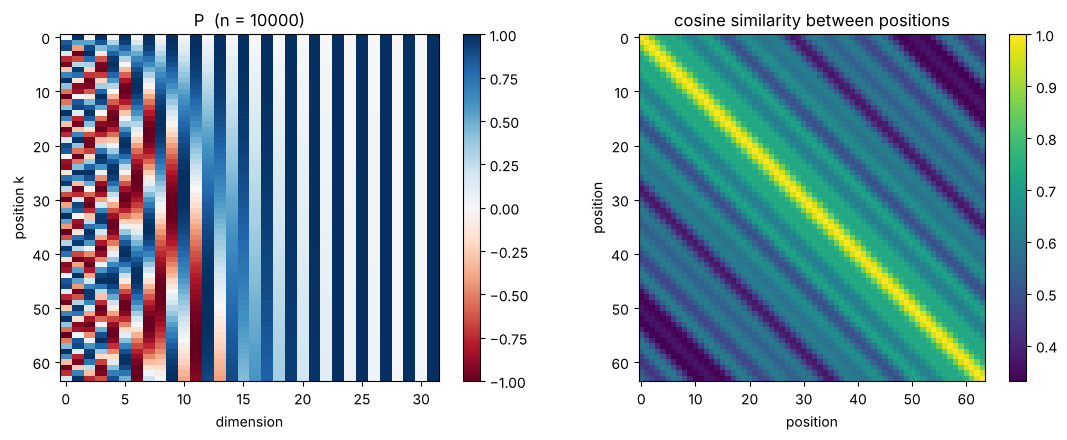

In [9]:
def plot_position_embeddings(seq_len=64, d=32, n=10000):
    P = sinusoidal_position_embedding(seq_len, d, n)
    Pn = F.normalize(P, dim=1)
    fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
    im = axs[0].imshow(P, cmap='RdBu', aspect='auto')
    axs[0].set_xlabel('dimension'); axs[0].set_ylabel('position k'); axs[0].set_title(f'P  (n = {n})')
    plt.colorbar(im, ax=axs[0])
    im = axs[1].imshow(Pn @ Pn.T, cmap='viridis')
    axs[1].set_xlabel('position'); axs[1].set_ylabel('position'); axs[1].set_title('cosine similarity between positions')
    plt.colorbar(im, ax=axs[1])
    plt.tight_layout(); plt.show()


plot_position_embeddings(n=10000)

### Questions 3

1. In the left plot, the columns on the left change quickly from one position to the next and the columns on
   the right change slowly. Why? (Hint: look at $n^{2i/d}$ for small and large $i$.)
2. In the right plot (with $n = 10{,}000$), which positions are most similar to each other? Why is that useful?
3. ViT does not use sinusoidal embeddings but **learned** ones: one trainable vector per position. Give one
   advantage and one disadvantage (Lecture 12, Section 4.3).

> ### ✅ Solution and discussion
> 1. Column pair $i$ is a sine and cosine of $k / n^{2i/d}$. For small $i$ the divisor is close to 1, so the angle grows by about one
>    radian per position: a fast rotation. For large $i$ the divisor is large (up to almost $n$), so the angle grows very slowly. Each
>    pair rotates at its own speed, from fast to slow, like the digits of a counter.
> 2. Neighbouring positions (near the diagonal) are the most similar, and similarity drops with distance (in the plot, from about 0.96
>    for neighbours to about 0.4 for positions 50 apart). So the embeddings tell
>    the model not only *where* a token is, but also which tokens are *close* to each other.
> 3. **Advantage:** the model learns whatever position code works best for the task (they tend to do slightly better). **Disadvantage:**
>    there is one vector per position seen in training, so they do not extend to longer sequences (or, for ViT, larger images with
>    more patches) without interpolation; sinusoidal embeddings are defined for any position.

### Position embeddings break the symmetry

Back to Part 2: we add the position embeddings to the tokens **before** the self-attention, and shuffle again.

In [10]:
P = sinusoidal_position_embedding(6, d).unsqueeze(0)             # (1, 6, 16)
with torch.no_grad():
    out, _ = self_attention(X + P, X + P, X + P)
    Xs = X[:, shuffle] + P                                       # shuffled tokens, positions added after shuffling
    out_shuffled, _ = self_attention(Xs, Xs, Xs)

print('With position embeddings: shuffled output == original output, shuffled?',
      torch.allclose(out_shuffled, out[:, shuffle], atol=1e-6))

With position embeddings: shuffled output == original output, shuffled? False


**Question.** Why is the answer now `False`? Why do we add $P$ *after* shuffling the tokens?

> ### ✅ Solution and discussion
> The position embeddings are tied to the **positions** $0, \ldots, 5$, not to the tokens. After shuffling, each token sits at a new
> position and gets a different $P[k]$ added, so its query, key and value change, and so does the output. The model now "sees" the
> order. We add $P$ after shuffling because that is what happens in reality: a shuffled sentence or image is a new input, and the
> position embeddings are always added by position.

---
# Part 4 — Why patches? (on paper)

The attention matrix $QK^T$ has one entry per pair of tokens: $n^2$ entries for $n$ tokens (Lecture 12,
Section 2.2). Fill in the table for one $224 \times 224$ image, one head and one layer.

**Swin** (Section 7.2) uses patches of $P = 4$ but computes attention only inside windows of $M \times M = 7 \times 7$
patches: each window is an attention matrix of $49 \times 49$ entries, and there are (number of patches) / 49 windows.

| Tokens | Number of tokens $n$ | Entries in the attention matrix |
|---|---|---|
| every pixel is a token | | |
| ViT patches, $P = 16$ | | |
| ViT patches, $P = 4$ | | |
| Swin, $P = 4$, windows of $7 \times 7$ patches | (same as above) | |

Then answer:

1. How much smaller is the attention matrix with $P = 16$ than with pixels?
2. How many times cheaper is Swin's window attention than global attention, for $P = 4$? How does the cost of
   each grow if the image gets twice as wide and twice as high?

> ### ✅ Solution and discussion
> | Tokens | Number of tokens $n$ | Entries in the attention matrix |
> |---|---|---|
> | every pixel is a token | $224^2 = 50{,}176$ | $50{,}176^2 \approx 2.5 \times 10^9$ |
> | ViT patches, $P = 16$ | $(224/16)^2 = 14^2 = 196$ | $196^2 = 38{,}416$ |
> | ViT patches, $P = 4$ | $(224/4)^2 = 56^2 = 3{,}136$ | $3{,}136^2 = 9{,}834{,}496 \approx 10^7$ |
> | Swin, $P = 4$, windows of $7 \times 7$ | $3{,}136$ (in $3{,}136 / 49 = 64$ windows) | $64 \times 49^2 = 153{,}664$ |
>
> 1. $2.5 \times 10^9 / 38{,}416 \approx 65{,}000$ times smaller ($= 16^4$, because $n$ shrinks by $16^2$ and the matrix by $16^4$).
> 2. $9{,}834{,}496 / 153{,}664 = 64$ times cheaper (= the number of windows). If the image gets 2 × 2 larger, the number of patches
>    grows 4 times: global attention becomes $4^2 = 16$ times more expensive (quadratic), Swin only 4 times (4 times as many windows of
>    the same size: linear).

---
# Part 5 — Exam-style questions

**Q1.** In scaled dot-product attention, $\text{softmax}(QK^T/\sqrt{d_k})\,V$, what are the attention weights for one query?

* (a) The values, scaled by $\sqrt{d_k}$.
* (b) A probability distribution over the keys: non-negative numbers that sum to 1.
* (c) The dot products between the query and the values.
* (d) A one-hot vector that selects exactly one value.

**Q2.** Why are the scores divided by $\sqrt{d_k}$?

* (a) To keep the dot products from growing with the key dimension, which would saturate the softmax and make its gradients vanish.
* (b) To make the attention weights sum to 1.
* (c) To reduce the memory needed for the attention matrix.
* (d) To make the attention matrix symmetric.

**Q3.** The tokens of a self-attention layer (without position embeddings) are fed in a different order. What happens to the output?

* (a) It changes completely.
* (b) It stays exactly the same, in the original order.
* (c) It is the same set of output vectors, in the new order.
* (d) It becomes zero.

**Q4.** A $224 \times 224$ image is cut into patches of $16 \times 16$ pixels. How many entries does the attention matrix of one head have?

* (a) 196
* (b) 38,416
* (c) 50,176
* (d) 2.5 billion

**Q5.** What makes Swin Transformer's attention cost grow only linearly with the image size?

* (a) It uses larger patches for larger images.
* (b) It computes attention only within fixed-size windows of patches.
* (c) It removes the softmax.
* (d) It uses a CNN instead of attention.

> ### ✅ Solution and discussion
> * **Q1: (b).**
> * **Q2: (a).**
> * **Q3: (c).** Self-attention is permutation equivariant (Part 2).
> * **Q4: (b).** 196 tokens, $196^2 = 38{,}416$ (Part 4).
> * **Q5: (b).**